# Analyse des ventes 2025 – Chaîne de boutiques « Teranga Market » (Dakar)

**Objectif** : transformer des données de ventes brutes en indicateurs et en recommandations utiles
pour la direction commerciale.

**Démarche** : 1) audit de la qualité des données, 2) nettoyage, 3) analyse SQL, 4) analyse Python
et visualisations, 5) insights et recommandations.

> ⚠️ Données **simulées** à des fins d'apprentissage (entreprise fictive). Les erreurs présentes dans le
> fichier brut (doublons, formats incohérents, fautes de saisie) ont été introduites volontairement.

In [7]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 120)
MOIS = ["Janv", "Févr", "Mars", "Avr", "Mai", "Juin", "Juil", "Août", "Sept", "Oct", "Nov", "Déc"]
BLEU, ORANGE, VERT, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.axisbelow": True, "figure.dpi": 110})

ventes_brutes = pd.read_csv("/content/sample_data/data/ventes_brutes_2025.csv", dtype=str)
boutiques = pd.read_csv("/content/sample_data/data/boutiques.csv")
produits = pd.read_csv("/content/sample_data/data/produits.csv")
print(ventes_brutes.shape)
ventes_brutes.head()

(28892, 7)


,transaction_id,date,boutique_id,produit_id,quantite,prix_unitaire,mode_paiement
0,T111994,2025-06-03,b01,P05,1,3000,Especes
1,T102941,2025-02-09,B02,P08,2,2000,cash
2,T109715,2025-05-08,B02,P16,4,5000,WAVE
3,T117692,2025-08-14,B04,P16,2,5000,wave
4,T126104,2025-12-06,B04,P08,2,2000,OM


## 1. Audit de la qualité des données

In [8]:
audit = {
    "Lignes": len(ventes_brutes),
    "Doublons exacts": int(ventes_brutes.duplicated().sum()),
    "Quantités manquantes": int((ventes_brutes["quantite"].fillna("") == "").sum()),
    "Codes boutique non standard": int((~ventes_brutes["boutique_id"].isin(boutiques["boutique_id"])).sum()),
    "Dates au format JJ/MM/AAAA": int(ventes_brutes["date"].str.contains("/").sum()),
    "Prix non numériques": int((~ventes_brutes["prix_unitaire"].str.fullmatch(r"\d+")).sum()),
}
print(pd.Series(audit))
print("\nModes de paiement saisis :", sorted(ventes_brutes["mode_paiement"].unique()))

Lignes                         28892
Doublons exacts                  426
Quantités manquantes             284
Codes boutique non standard     6383
Dates au format JJ/MM/AAAA      4353
Prix non numériques              541
dtype: int64

Modes de paiement saisis : ['Carte', 'Carte bancaire', 'Especes', 'Espèces', 'OM', 'Orange Money', 'WAVE', 'Wave', 'cash', 'orange money', 'wave']


## 2. Nettoyage
Chaque règle est documentée et son impact est mesuré.

In [9]:
df = ventes_brutes.copy()
journal = []

# 2.1 Doublons
avant = len(df); df = df.drop_duplicates(); journal.append(("Suppression des doublons", avant - len(df)))

# 2.2 Dates : deux formats -> un seul
iso = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")
fr = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="coerce")
df["date"] = iso.fillna(fr)

# 2.3 Codes boutique : majuscules, sans espaces ni tirets, zéro manquant
df["boutique_id"] = (df["boutique_id"].str.upper().str.strip().str.replace("-", "", regex=False)
                     .str.replace(r"^B(\d)$", r"B0\1", regex=True))

# 2.4 Modes de paiement harmonisés
correspondance = {"especes": "Espèces", "espèces": "Espèces", "cash": "Espèces", "wave": "Wave",
                  "orange money": "Orange Money", "om": "Orange Money",
                  "carte": "Carte", "carte bancaire": "Carte"}
df["mode_paiement"] = df["mode_paiement"].str.strip().str.lower().map(correspondance)

# 2.5 Prix : retirer « FCFA » et les espaces, puis contrôler avec le catalogue
df["prix_unitaire"] = pd.to_numeric(df["prix_unitaire"].str.replace(r"[^\d]", "", regex=True))
df = df.merge(produits[["produit_id", "prix_unitaire"]].rename(columns={"prix_unitaire": "prix_catalogue"}),
              on="produit_id", how="left")
erreurs_prix = df["prix_unitaire"] != df["prix_catalogue"]
journal.append(("Prix aberrants corrigés par le prix catalogue", int(erreurs_prix.sum())))
df["prix_unitaire"] = df["prix_catalogue"]; df = df.drop(columns="prix_catalogue")

# 2.6 Quantités : manquantes -> supprimées ; négatives (retours) -> mises à part
df["quantite"] = pd.to_numeric(df["quantite"], errors="coerce")
manq = df["quantite"].isna(); journal.append(("Lignes sans quantité supprimées", int(manq.sum())))
df = df[~manq]
retours = df[df["quantite"] < 0]; journal.append(("Retours (quantité négative) mis à part", len(retours)))
df = df[df["quantite"] > 0].copy()

df["quantite"] = df["quantite"].astype(int)
df["montant"] = df["quantite"] * df["prix_unitaire"]
df = df.merge(produits[["produit_id", "nom_produit", "categorie"]], on="produit_id") \
       .merge(boutiques[["boutique_id", "nom"]].rename(columns={"nom": "boutique"}), on="boutique_id")

assert df[["date", "boutique", "mode_paiement", "montant"]].notna().all().all()
print(pd.DataFrame(journal, columns=["Règle", "Lignes concernées"]).to_string(index=False))
print(f"\nJeu propre : {len(df):,} transactions".replace(",", " "))
df.to_csv("/content/sample_data/data/ventes_propres_2025.csv", index=False)

                                        Règle  Lignes concernées
                     Suppression des doublons                426
Prix aberrants corrigés par le prix catalogue                 91
              Lignes sans quantité supprimées                278
       Retours (quantité négative) mis à part                 92

Jeu propre : 28 096 transactions


## 3. Analyse SQL
Les données propres sont chargées dans une base SQLite. Les mêmes requêtes figurent dans `requetes.sql`.

In [10]:
con = sqlite3.connect(":memory:")
df.assign(date=df["date"].dt.strftime("%Y-%m-%d")).to_sql("ventes", con, index=False)
boutiques.to_sql("boutiques", con, index=False); produits.to_sql("produits", con, index=False)

def sql(requete):
    return pd.read_sql_query(requete, con)

In [11]:
# Q1 – Chiffre d'affaires, nombre de ventes et panier moyen par boutique
sql("""
SELECT b.nom AS boutique,
       SUM(v.montant)                    AS ca_fcfa,
       COUNT(*)                          AS nb_ventes,
       ROUND(AVG(v.montant))             AS panier_moyen,
       ROUND(SUM(v.montant) * 1.0 / b.surface_m2) AS ca_par_m2
FROM ventes v JOIN boutiques b ON b.boutique_id = v.boutique_id
GROUP BY b.nom ORDER BY ca_fcfa DESC
""")

,boutique,ca_fcfa,nb_ventes,panier_moyen,ca_par_m2
0,Plateau,54200200,5900,9186.0,301112.0
1,Parcelles Assainies,48941300,5728,8544.0,305883.0
2,Pikine,46168900,4956,9316.0,307793.0
3,Médina,40599400,4484,9054.0,289996.0
4,Almadies,34830700,3884,8968.0,290256.0
5,Rufisque,29191300,3144,9285.0,265375.0


In [12]:
# Q2 – Part de chaque catégorie dans le chiffre d'affaires
sql("""
SELECT categorie,
       SUM(montant) AS ca_fcfa,
       ROUND(100.0 * SUM(montant) / (SELECT SUM(montant) FROM ventes), 1) AS part_pct
FROM ventes GROUP BY categorie ORDER BY ca_fcfa DESC
""")

,categorie,ca_fcfa,part_pct
0,Alimentation,130799600,51.5
1,Électroménager,50785500,20.0
2,Téléphonie,40554000,16.0
3,Hygiène & beauté,19344300,7.6
4,Boissons,12448400,4.9


In [13]:
# Q3 – Top 5 des produits par chiffre d'affaires (fonction de fenêtrage)
sql("""
WITH ca AS (SELECT nom_produit, categorie, SUM(montant) AS ca_fcfa FROM ventes GROUP BY nom_produit)
SELECT RANK() OVER (ORDER BY ca_fcfa DESC) AS rang, nom_produit, categorie, ca_fcfa
FROM ca ORDER BY rang LIMIT 5
""")

,rang,nom_produit,categorie,ca_fcfa
0,1,Riz brisé 25 kg,Alimentation,72602000
1,2,Ventilateur sur pied,Électroménager,35310000
2,3,Huile végétale 5 L,Alimentation,29133000
3,4,Écouteurs Bluetooth,Téléphonie,18960000
4,5,Fer à repasser,Électroménager,15475500


In [14]:
# Q4 – Évolution trimestrielle de la part du mobile money (Wave + Orange Money), en % du nombre de ventes
sql("""
SELECT 'T' || ((CAST(strftime('%m', date) AS INTEGER) + 2) / 3) AS trimestre,
       ROUND(100.0 * SUM(mode_paiement IN ('Wave', 'Orange Money')) / COUNT(*), 1) AS part_mobile_money_pct,
       ROUND(100.0 * SUM(mode_paiement = 'Espèces') / COUNT(*), 1)                 AS part_especes_pct
FROM ventes GROUP BY trimestre ORDER BY trimestre
""")

,trimestre,part_mobile_money_pct,part_especes_pct
0,T1,38.2,56.2
1,T2,44.4,49.6
2,T3,50.8,43.8
3,T4,55.9,37.8


## 4. Analyse Python et visualisations

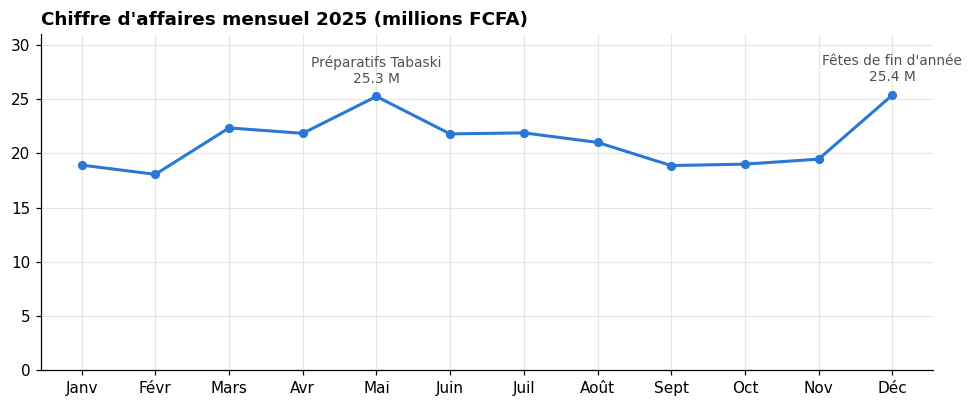

In [17]:
mensuel = df.groupby(df["date"].dt.to_period("M"))["montant"].sum() / 1e6
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(MOIS, mensuel.values, color=BLEU, lw=2, marker="o", ms=5)
for m, texte in [(4, "Préparatifs Tabaski"), (11, "Fêtes de fin d'année")]:
    ax.annotate(f"{texte}\n{mensuel.iloc[m]:.1f} M", (m, mensuel.iloc[m]), xytext=(0, 9),
                textcoords="offset points", ha="center", color="#52514e", fontsize=9)
ax.set_title("Chiffre d'affaires mensuel 2025 (millions FCFA)", loc="left", fontweight="bold")
ax.set_ylim(0, 31); plt.tight_layout(); plt.savefig("figures/ca_mensuel.png"); plt.show()

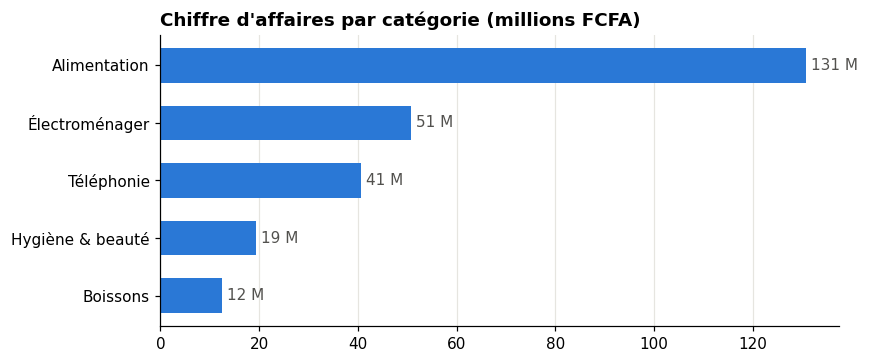

In [20]:
cat = df.groupby("categorie")["montant"].sum().sort_values() / 1e6
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(cat.index, cat.values, color=BLEU, height=0.6)
for i, v in enumerate(cat.values):
    ax.text(v + 1, i, f"{v:.0f} M", va="center", color="#52514e")
ax.set_title("Chiffre d'affaires par catégorie (millions FCFA)", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.savefig("/content/sample_data/figures/ca_categorie.png"); plt.show()

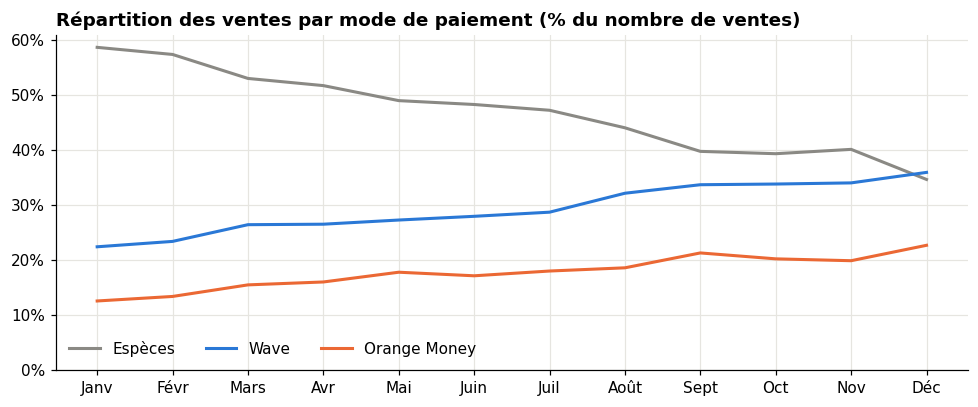

In [21]:
paiement = (df.groupby([df["date"].dt.to_period("M"), "mode_paiement"]).size()
              .unstack().pipe(lambda t: t.div(t.sum(axis=1), axis=0) * 100))
fig, ax = plt.subplots(figsize=(9, 3.8))
for col, couleur in [("Espèces", GRIS), ("Wave", BLEU), ("Orange Money", ORANGE)]:
    ax.plot(MOIS, paiement[col], color=couleur, lw=2, label=col)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0); ax.legend(frameon=False, ncol=3, loc="lower left")
ax.set_title("Répartition des ventes par mode de paiement (% du nombre de ventes)", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("/content/sample_data/figures/modes_paiement.png"); plt.show()

In [22]:
# Effet Tabaski (6 juin 2025) : ventes alimentaires des 14 jours précédents vs le reste de l'année
alim = df[df["categorie"] == "Alimentation"].groupby("date")["montant"].sum()
fenetre = (alim.index >= "2025-05-23") & (alim.index <= "2025-06-06")
hausse = alim[fenetre].mean() / alim[~fenetre].mean() - 1
print(f"CA alimentaire journalier moyen avant Tabaski : +{hausse:.0%} par rapport au reste de l'année")

# Effet week-end
jour = df.groupby("date")["montant"].sum()
we = jour[jour.index.dayofweek >= 5].mean() / jour[jour.index.dayofweek < 5].mean() - 1
print(f"CA journalier moyen le week-end : +{we:.0%} par rapport à la semaine")

CA alimentaire journalier moyen avant Tabaski : +80% par rapport au reste de l'année
CA journalier moyen le week-end : +35% par rapport à la semaine


## 5. Insights et recommandations

Les chiffres ci-dessous sont recalculés à chaque exécution.

In [23]:
ca_total = df["montant"].sum()
top_b = df.groupby("boutique")["montant"].sum().sort_values(ascending=False)
mm = paiement[["Wave", "Orange Money"]].sum(axis=1)
def n(x):
    return f"{x:,.0f}".replace(",", " ")

ca_m2 = (df.groupby("boutique")["montant"].sum() / boutiques.set_index("nom")["surface_m2"]).sort_values()
print(f"""
• CA 2025 : {n(ca_total/1e6)} M FCFA, {n(len(df))} ventes, panier moyen {n(df['montant'].mean())} FCFA.
• {top_b.index[0]} est la boutique n°1 ({top_b.iloc[0]/ca_total:.0%} du CA) ; {top_b.index[-1]} ferme la marche ({top_b.iloc[-1]/ca_total:.0%}).
• L'alimentation pèse {cat['Alimentation']/cat.sum():.0%} du CA ; la période Tabaski fait bondir ses ventes de {hausse:.0%}.
• Le mobile money passe de {mm.iloc[0]:.0f} % des ventes en janvier à {mm.iloc[-1]:.0f} % en décembre.

Recommandations :
1. Anticiper les stocks alimentaires (riz, huile, oignons) 3 semaines avant la Tabaski.
2. Renforcer le personnel en caisse le week-end (+{we:.0%} de CA).
3. Négocier les commissions Wave / Orange Money et lancer une offre de fidélité liée au paiement mobile.
4. Ne pas juger les boutiques au seul CA : rapporté à la surface, la plus faible est {ca_m2.index[0]}
   ({n(ca_m2.iloc[0])} FCFA/m²) et la meilleure {ca_m2.index[-1]} ({n(ca_m2.iloc[-1])} FCFA/m²).
   Revoir l'assortiment et la visibilité de {ca_m2.index[0]} en priorité.
""")


• CA 2025 : 254 M FCFA, 28 096 ventes, panier moyen 9 038 FCFA.
• Plateau est la boutique n°1 (21% du CA) ; Rufisque ferme la marche (11%).
• L'alimentation pèse 52% du CA ; la période Tabaski fait bondir ses ventes de 80%.
• Le mobile money passe de 35 % des ventes en janvier à 59 % en décembre.

Recommandations :
1. Anticiper les stocks alimentaires (riz, huile, oignons) 3 semaines avant la Tabaski.
2. Renforcer le personnel en caisse le week-end (+35% de CA).
3. Négocier les commissions Wave / Orange Money et lancer une offre de fidélité liée au paiement mobile.
4. Ne pas juger les boutiques au seul CA : rapporté à la surface, la plus faible est Rufisque
   (265 375 FCFA/m²) et la meilleure Pikine (307 793 FCFA/m²).
   Revoir l'assortiment et la visibilité de Rufisque en priorité.

